In [28]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [29]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

import pandas as pd

In [30]:
### Create function for Cressman Analysis ###
def cressman(dist: float, roi: float) -> float:
    """
    Function to analyze the value at a given point from other data
    using a Cressman analysis technique.
    
    inputs:
      dist = distance between the analysis point and the observation point
      roi = the radius of influence 
      
    returns:
      out = value of the Cressman weight function
    """
    out = 0
    if(dist <= roi):
      num = (roi ** 2) - (dist ** 2)
      denom = (roi ** 2) + (dist ** 2)
      out = num / denom

    return out

In [66]:
### Create function for bilinear interpolation ###

# I believe bilinear interpolation is literally just what we did last time?
# Like, the exact matrix equation. It's just that now we're using analysis values to interpolate observation values, instead of the other way around


# This is wrong!! This is a polynomial fit for a second-order polynomial when we need to fit a FIRST-order polynomial !!! !!! !!! !!! !!! !!! !!!
# We will fit to ONLY the NEAREST FOUR POINTS (top left, top right, bottom left, bottom right), NOT all the points in the RoI
# Doing this will be easiest with floor & ceiling functions and then adding one to the indices (it will be easiest with a list of normalized grid points
# so that the index of a point's x- or y-value is also its coordinate, e.g. x[0] = 0, x[1] = 1, etc.) (this is INDEX SPACE)

def toIndexSpace(x: np.ndarray or float, x0: float) -> np.ndarray or float:
    delta = .0127
    return ( (x - x0) / delta )

def toRealSpace(ind: np.ndarray or float, x0: float) -> np.ndarray or float:
    delta = .0127
    return x0 + (ind * delta)

def bilinearInterpolate(xo: float, yo: float, xGrid: np.ndarray, yGrid: np.ndarray, analysisArr: np.ndarray) -> float:
    
    # Defining the values at the origin of index space
    x0 = .25
    y0 = -.155

    # Transform the grid of analysis points into index space
    xIndices = toIndexSpace(xGrid, x0)
    yIndices = toIndexSpace(yGrid, y0)

    # Transform the observation point into index space
    xoIndex = toIndexSpace(xo, x0)
    yoIndex = toIndexSpace(yo, y0)

    # Calculate the x- and y-indices of the four points surrounding the observation point
    x1 = int(np.floor(xoIndex))
    x2 = int(np.ceil(xoIndex))
    y1 = int(np.floor(yoIndex))
    y2 = int(np.ceil(yoIndex))

    # Use the indices to find the analysis values at the four analysis points
    tlVal = analysisArr[x1][y1]
    trVal = analysisArr[x2][y1]
    blVal = analysisArr[x1][y2]
    brVal = analysisArr[x2][y2]

    # Construct the component matrices of the matrix-form bilinear interpolation equation (see the cell below)
    matX = np.array([xGrid[x2] - xo, xo - xGrid[x1]])
    matQ = np.array([[tlVal, trVal], [brVal, blVal]])
    matY = np.array([[yGrid[y2] - yo], [yo - yGrid[y1]]])

    print(xo)

    # Calculate the analysis value at the observation point with some matrix multiplications (and an index because it returns a 1x1 numpy array and I want a float !!!)
    output = (matX @ matQ @ matY)[0]
    
    return output


print(bilinearInterpolate(obsx[0], obsy[0], x, y, graphZ1))




0.2729661413949601
0.8874890405333407


The bilinear interpolation equation is 
$$
f(x,y) = \frac{1}{(x_2 - x_1)(y_2 - y_1)}
\begin{bmatrix}
x_2 - x & x - x_1
\end{bmatrix}
\begin{bmatrix}
f(Q_{11}) & f(Q_{12}) \\
f(Q_{21}) & f(Q_{22})
\end{bmatrix}
\begin{bmatrix}
y_2 - y \\
y - y_1
\end{bmatrix}.
$$
We omit the fraction at the beginning because the denominator evaluates to 1 (an advantage of index space) so the whole fraction reduces to 1.

In [32]:
### Read in observations ###

# SID LAT LON HGT DIR SPD
# 0   1   2   3   4   5

# I think you'll have to change this if you're grading on a non-UNIX machine... sorry
observation_file = r"../RAOBs_201903131200.txt"


# This reads the data as comma-separated values, creating a pandas dataframe that is subsequently converted into a numpy array for easy manipulation later.
# Oh and it has no headers, which also makes things easier later.
observations = pd.read_csv(observation_file, header=None).to_numpy()

print(observations[:,3].shape)

(135,)


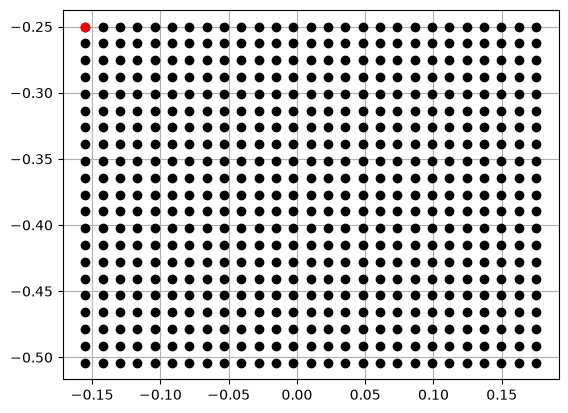

In [33]:
### Set up analysis map with a 21x27 rectangular grid of points ###
''' We have a polar stereographic projection with a standard latitude of 60degN and a standard latitude of 100degW. Map scale is 1/15,000,000. 
    We need our origin at 90degN latitude and 0deg longitude, with grid points every 1.27cm extending to x = +- 25cm and y = +- 15.5cm.
    The first array member (0,0) is supposed to be at x = 25cm, y = -15.5cm.
'''

#np array element format: array[col][row], both starting at zero

# Init lists of x- & y-values
x = []
y = []

# x- & y-values at (0,0)
x0 = .25
y0 = -.155

# Populating the x & y lists with all the values on the grid
# You will note that all cm values have been converted to m
for i in range(27):
    diff = i * .0127
    if(i < 21):
        x.append(x0 + diff)
    y.append(y0 + diff)

x = np.array(x)
y = np.array(y)

# Use the x- & y-values to populate two new numpy arrays with the values necessary to actually graph all gridpoints
gridx, gridy = np.meshgrid(x,y)

testx = [-.25]
testy = [-.155]

# Plot the grid of values, to ensure that we made it correctly
fig, ax = plt.subplots()
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
ax.plot(testy, testx, marker='o', color='r', linestyle='none')
ax.grid()
plt.show()


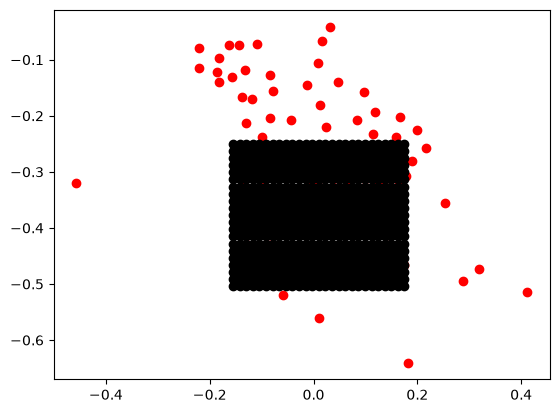

In [34]:
### convert obs lat/long to x,y ###

# Conversion factor we need cuz numpy trig fcns are in radians
degToRad = np.pi / 180

# Defining our standard latitude & longitude
standardLat = 60 * degToRad
standardLong = -100 * degToRad

# Earth's mean radius, in meters
rho = 6.371e6

# Map scale
m = 1 / 15e6

# Helper function for calculating scale factor
def __scaleFactor__(lat: float) -> float:
    sigmaNumerator = 1 + np.sin(standardLat)
    sigmaDenominator = 1 + np.sin(lat)

    return (sigmaNumerator / sigmaDenominator)

# Defining a function to convert from lat/long to x/y
def getCartesian(latDeg: float, longDeg: float) -> (float,float):
    lat = latDeg * degToRad
    long = (longDeg * degToRad) - standardLong
    sigma = __scaleFactor__(lat)
    r = m * rho * sigma * np.cos(lat)
    x = r * np.cos(long)
    y = r * np.sin(long)

    return x,y



# Initializing lists for the x- & y-values we will calculate from the observation lat/long
obsx = []
obsy = []

for i in range(observations.shape[0]):
    tempx, tempy = getCartesian(observations[i][1], observations[i][2])
    obsx.append(tempx)
    obsy.append(tempy)

# Turning lists into np arrays because they're much nicer to work with
obsx = np.array(obsx, dtype=np.double)
obsy = np.array(obsy, dtype=np.double)

# Check points with a graph
fig, ax = plt.subplots()
ax.plot(obsy, -obsx, marker='o', color='r', linestyle='none')
ax.plot(gridy, -gridx, marker='o', color='k', linestyle='none')
plt.show()

# The points do appear to be in the correct locations

In [ ]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin

def analyze(xa: float, ya: float, xArr: np.ndarray, yArr: np.ndarray, obsArr: np.ndarray, roi: float, bgArr: np.ndarray, bgVal: float or None, first=False) -> float:
    '''
    Do a Cressman analysis at point (xa, ya) based on input observations. If no background is provided, the analysis runs without one using an alternate analysis function. 
    '''
    
    # Make arrays of the (signed) x- & y-distance between the analysis point and the observation points in the RoI
    xDist = xa - xArr
    yDist = ya - yArr
    
    # Initializing an empty np array that will be filled with the weights
    weights = np.ndarray((obsArr.shape[0],))

    # Populating the weights array using the cressman function we defined waaay back at the beginning
    for i in range(obsArr.shape[0]):
        dist = np.hypot(xDist[i], yDist[i])
        weights[i] = cressman(dist, roi)

    # Initializing a couple variables that get their real value in a conditional later
    num = 0
    firstTerm = 0
    # Picking the right analysis function based on whether this is the first iteration or not
    if(first):
        # First-iteration numerator is only the sum of the weighted observations
        num = (weights * obsArr).sum()
    else:
        # Later-iteration numerators are the sum of the weighted observation increments
        bgArr = np.nan_to_num(bgArr)
        num = (weights * (obsArr - bgArr)).sum()
        # Also, we now have to add the background value to our analysis
        firstTerm = bgVal
    
    # Defining the denominator of the fraction in the analysis function
    denom = weights.sum()

    # Finally evaluate the analysis function and return it
    output = firstTerm + (num / denom)

    return output

def getdmin(x: np.ndarray, y: np.ndarray) -> float:
    # For each point provided, calculate the smallest distance to any other point, then average all of them.
    
    # Create an array of all the observation points, then transpose it so it's actuall a column vector
    points = np.array([x,y]).T

    # Create an empty array that we will fill with distances as we calcuate
    minimumDistances = np.ndarray((points.shape[0], ))

    # Iterate over all points i
    for i in range(points.shape[0]):
        # Initialize the minimum distance variable with an absurd number so that all the distances are less than it
        minDist = 1e100

        # Iterate over all points j 
        for j in range(i, points.shape[0]):
            # Calculate the distance between point i and point j
            dist = np.hypot(points[i][0] - points[j][0], points[i][1] - points[j][1])
            # The distance between a point and itself is zero so we skip it
            if(i == j):
                continue

            # If the distance between i and j is less than the current minimum distance, replace the current minimum distance with the distance between i and j
            if(dist < minDist):
                minDist = dist

        if(minDist > 1e10):
            minDist = 0
        minimumDistances[i] = minDist

    # Take the average of the minimum distances 
    dmin = minimumDistances.mean()        
    return dmin


# print(analyze(x[0],y[0], obsx, obsy, observations[:,3], roi, a1background, currBgVal))

[8.87489041e-01 5.68750192e+03 8.72656685e-01 5.66144852e+03
 5.60180712e+03 5.58316485e+03            nan 5.52368026e+03
 5.65502343e+03 5.68901804e+03            nan 8.93541547e-01
 5.64688112e+03 8.76117642e-01 5.59824053e+03 5.69514361e+03
 5.56039898e+03 5.62417684e+03 5.66289769e+03 5.53250956e+03
 5.53398769e+03 5.60984178e+03 5.67994490e+03 8.72921986e-01
 5.67775727e+03 5.52673735e+03 8.98118875e-01 8.94226236e-01
 5.47096483e+03 9.16306330e-01 5.45847977e+03 8.96982780e-01
 9.07761709e-01 9.04808501e-01 5.48172897e+03 5.50899637e+03
 9.07872017e-01 9.19276763e-01 5.43972148e+03 8.91542443e-01
 9.24524687e-01 9.20643940e-01 8.83178473e-01 9.21059940e-01
            nan 9.11071067e-01 9.17572432e-01 8.96222559e-01
 5.42938473e+03 5.68599469e+03 9.28270767e-01 9.18085731e-01
 9.05126890e-01 8.95220285e-01 9.11299562e-01 8.95329015e-01
 8.95261835e-01 9.11425236e-01 9.12021256e-01 9.08479764e-01
 9.01983621e-01 9.39746870e-01 5.49011684e+03 9.26496644e-01
 8.91785503e-01 9.075819

In [36]:
### First analysis, no successive corrections ###

# Define our radius of influence
roi = 4 * getdmin(obsx, obsy)

# Create a list that will be populated with analysis values
analysis1 = []
graphZ1 = np.ndarray((len(x), len(y)))

# Calculate the analysis value at each analysis point
for i in range(len(x)):
    for j in range(len(y)):
        currVal = analyze(x[i], y[j], obsx, obsy, observations[:,3], roi, bgArr=None, bgVal=None, first=True)
        analysis1.append(currVal)
        graphZ1[i][j] = currVal

# Convert the analysis list into a fixed-size numpy array for easier calculation later
analysis1 = np.array(analysis1)



In [42]:
### Next Analyses ###

def isOutsideGrid(x: float, y: float) -> bool:
    return (x < .25) or (x > .504) or (y < -.155) or (y > .1752)


def backgroundFromAnalysis(analysis: np.ndarray) -> np.ndarray:
    background = []
    for i in range(len(obsx)):
        if(isOutsideGrid(obsx[i],obsy[i])):
            bgVal = analyze(obsx[i], obsy[i], gridx.flatten(), gridy.flatten(), analysis1, roi, bgArr=None, bgVal=None, first=True)
        else:
            bgVal = bilinearInterpolate(obsx[i], obsy[i], x, y, analysis)
        background.append(bgVal)
    background = np.array(background)

    return background

a1background = backgroundFromAnalysis(graphZ1)

analysis2 = []
graphZ2 = np.ndarray((len(x), len(y)))


for i in range(len(x)):
    for j in range(len(y)):
        currBgInd = (27 * i) + j
        currBgVal = analysis1[currBgInd]
        currVal = analyze(x[i],y[j], obsx, obsy, observations[:,3], roi, a1background, currBgVal)
        analysis2.append(currVal)
        graphZ2[i][j] = currVal

analysis2 = np.array(analysis2)

a2background = backgroundFromAnalysis(graphZ2)

analysis3 = []
graphZ3 = np.ndarray((len(x), len(y)))

for i in range(len(x)):
    for j in range(len(y)):
        currBgInd = (27 * i) + j
        currBgVal = analysis2[currBgInd]
        currVal = analyze(x[i],y[j], obsx, obsy, observations[:,3], roi, a2background, currBgVal)
        analysis3.append(currVal)
        graphZ3[i][j] = currVal

analysis3 = np.array(analysis3)


print(analysis2)

[ 8439.85071499  8555.44161086  8655.55247949  8723.97448075
  8802.57184311  8888.33452887  8970.44607056  9047.20099215
  9109.24637308  9165.61658622  9196.2637059   9223.94490244
  9264.90817918  9295.93254046  9333.1149275   9336.74078769
  9329.04052046  9307.6912553   9250.67913272  9186.21794825
  9120.9320043   9056.06243398  8965.66199817  8880.26174543
  8788.12618303  8696.08022597  8574.61324187  8968.93439781
  9052.76757955  9141.57183867  9196.65605404  9254.60977334
  9316.9816089   9385.24899555  9459.24945566  9519.42453125
  9579.55368642  9628.6029817   9659.6671737   9704.02708605
  9737.39188384  9768.22730566  9765.68422046  9748.78675556
  9711.27739533  9646.95052559  9575.55251439  9505.03002948
  9426.73877155  9328.05271423  9229.8362625   9126.60986002
  9010.44398467  8888.08288889  9445.67134059  9505.91909395
  9571.02923963  9618.56091878  9664.41333105  9712.7817319
  9757.2871151   9809.38914525  9866.32119029  9926.48781264
  9974.96176742 10031.039

/tmp/ipykernel_23024/2300587824.py:39: RuntimeWarning: invalid value encountered in scalar divide
  output = firstTerm + (num / denom)


In [38]:
### Calculate Analysis Differences

diff31 = analysis3 - analysis1
diff32 = analysis3 - analysis2
diff21 = analysis2 - analysis1

# print(diff31)
# print(diff32)
# print(diff21)


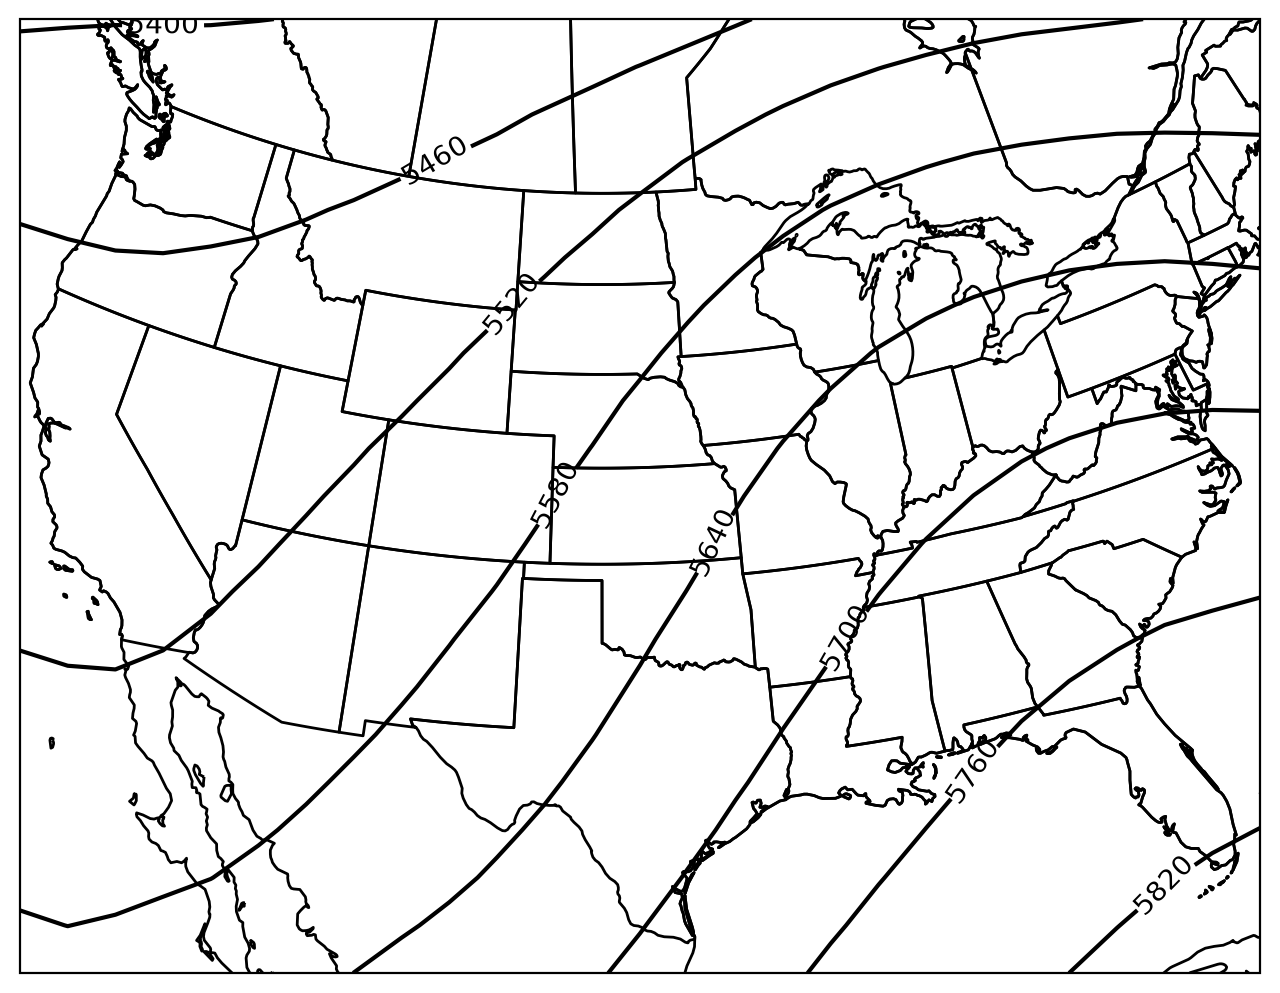

In [41]:
### Plot 500mb analyses over a map ###
#use old code...
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"] = "YES"

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=-100,central_latitude=90,true_scale_latitude=60,globe=globe)
fig = plt.figure(figsize=(8,8),dpi=200)
ax1 = fig.add_subplot(111,projection=proj)
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot analysis (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
cs1 = ax1.contour(gridy/100/m,-gridx/100/m,graphZ1.T,colors='k',levels=np.arange(0,8000,60),transform=proj)
plt.clabel(cs1,levels=np.arange(0,8000,60))

plt.show()

In [ ]:
### Plot Analysis Differences ###


In [ ]:
### Store the analyses in text files ###


In [ ]:
### Store the difference fields in text files ###


In [ ]:
### Store RMS values in text file ###


In [ ]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?
    

'''